# CIFAR-100 - CNN theo kiến trúc notebook mẫu

Đọc CIFAR-100 fine labels từ thư mục `cifar-100` cạnh notebook và huấn luyện CNN từ đầu, không dùng pretrained weights hay tải dataset.

- 45.000 ảnh train, 5.000 validation, 10.000 test; ảnh RGB 32 × 32, gồm 100 lớp fine.
- Mean/std riêng từng kênh được tính trên train; validation/test dùng cùng thống kê.
- Train augment: flip, crop, xoay, dịch chuyển, zoom và color jitter nhẹ.
- Tám Conv2D thường theo bốn block 32–64–128–256, kèm BatchNorm, MaxPooling, Dropout và L2 như notebook mẫu.
- Giảm learning rate và EarlyStopping dựa trên val_loss; checkpoint lưu theo val_loss thấp nhất.
- Chạy notebook từ đầu để huấn luyện lại trên CIFAR-100.

In [4]:
import tensorflow as tf

print(f"TensorFlow: {tf.__version__}")
print(tf.config.list_physical_devices("GPU"))

TensorFlow: 2.15.0
[]


Dataset CIFAR-100 được đọc trực tiếp từ thư mục `cifar-100` nằm cạnh notebook (các file `train`, `test` và `meta`); không tải dữ liệu qua Internet. Ảnh được chuyển thành tensor TensorFlow để dùng trong pipeline hiện có.

In [5]:
from pathlib import Path
import pickle

import numpy as np

project_dir_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "fruit-detection"]
PROJECT_DIR = next(
    (path.resolve() for path in project_dir_candidates
     if (path / "build_cnn_cifar_100.ipynb").is_file()),
    Path.cwd().resolve(),
)
DATA_DIR = PROJECT_DIR / "cifar-100"

required_files = (DATA_DIR / "train", DATA_DIR / "test", DATA_DIR / "meta")
missing_files = [path for path in required_files if not path.is_file()]
if missing_files:
    missing_paths = "\n".join(str(path) for path in missing_files)
    raise FileNotFoundError(
        f"Không tìm thấy file CIFAR-100 trong {DATA_DIR}. "
        f"Hãy đặt thư mục cifar-100 cạnh notebook. Thiếu:\n{missing_paths}"
    )

def load_cifar_batch(file_path):
    with file_path.open("rb") as file:
        batch = pickle.load(file, encoding="bytes")
    images = np.asarray(batch[b"data"], dtype=np.uint8).reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1).copy()
    labels = np.asarray(batch[b"fine_labels"], dtype=np.int32)
    return images, labels

x_train, y_train = load_cifar_batch(DATA_DIR / "train")
x_test, y_test = load_cifar_batch(DATA_DIR / "test")
with (DATA_DIR / "meta").open("rb") as file:
    metadata = pickle.load(file, encoding="bytes")
class_names = [name.decode("utf-8") for name in metadata[b"fine_label_names"]]

x_train = tf.convert_to_tensor(x_train, dtype=tf.uint8)
y_train = tf.convert_to_tensor(y_train, dtype=tf.int32)
x_test = tf.convert_to_tensor(x_test, dtype=tf.uint8)
y_test = tf.convert_to_tensor(y_test, dtype=tf.int32)

print("Dataset: CIFAR-100 fine labels (loaded from local folder)")
print(f"Dataset directory: {DATA_DIR}")
print(f"Train images: {x_train.shape}, dtype={x_train.dtype}")
print(f"Train labels: {y_train.shape}, dtype={y_train.dtype}")
print(f"Test images : {x_test.shape}, dtype={x_test.dtype}")
print(f"Test labels : {y_test.shape}, dtype={y_test.dtype}")
print(f"Pixel range : {int(tf.reduce_min(x_train))} to {int(tf.reduce_max(x_train))}")
print(f"Classes ({len(class_names)}): {class_names}")

Dataset: CIFAR-100 fine labels (loaded from local folder)
Dataset directory: D:\22DT3\AI-Projects\fruit-detection\cifar-100
Train images: (50000, 32, 32, 3), dtype=<dtype: 'uint8'>
Train labels: (50000,), dtype=<dtype: 'int32'>
Test images : (10000, 32, 32, 3), dtype=<dtype: 'uint8'>
Test labels : (10000,), dtype=<dtype: 'int32'>
Pixel range : 0 to 255
Classes (100): ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree', 'plain',

## Preview ảnh gốc trước augmentation

Hiển thị một ảnh CIFAR-100 gốc cho mỗi class, lấy trực tiếp từ `x_train` và `y_train`. Cell này chạy trước khi tạo pipeline augmentation.

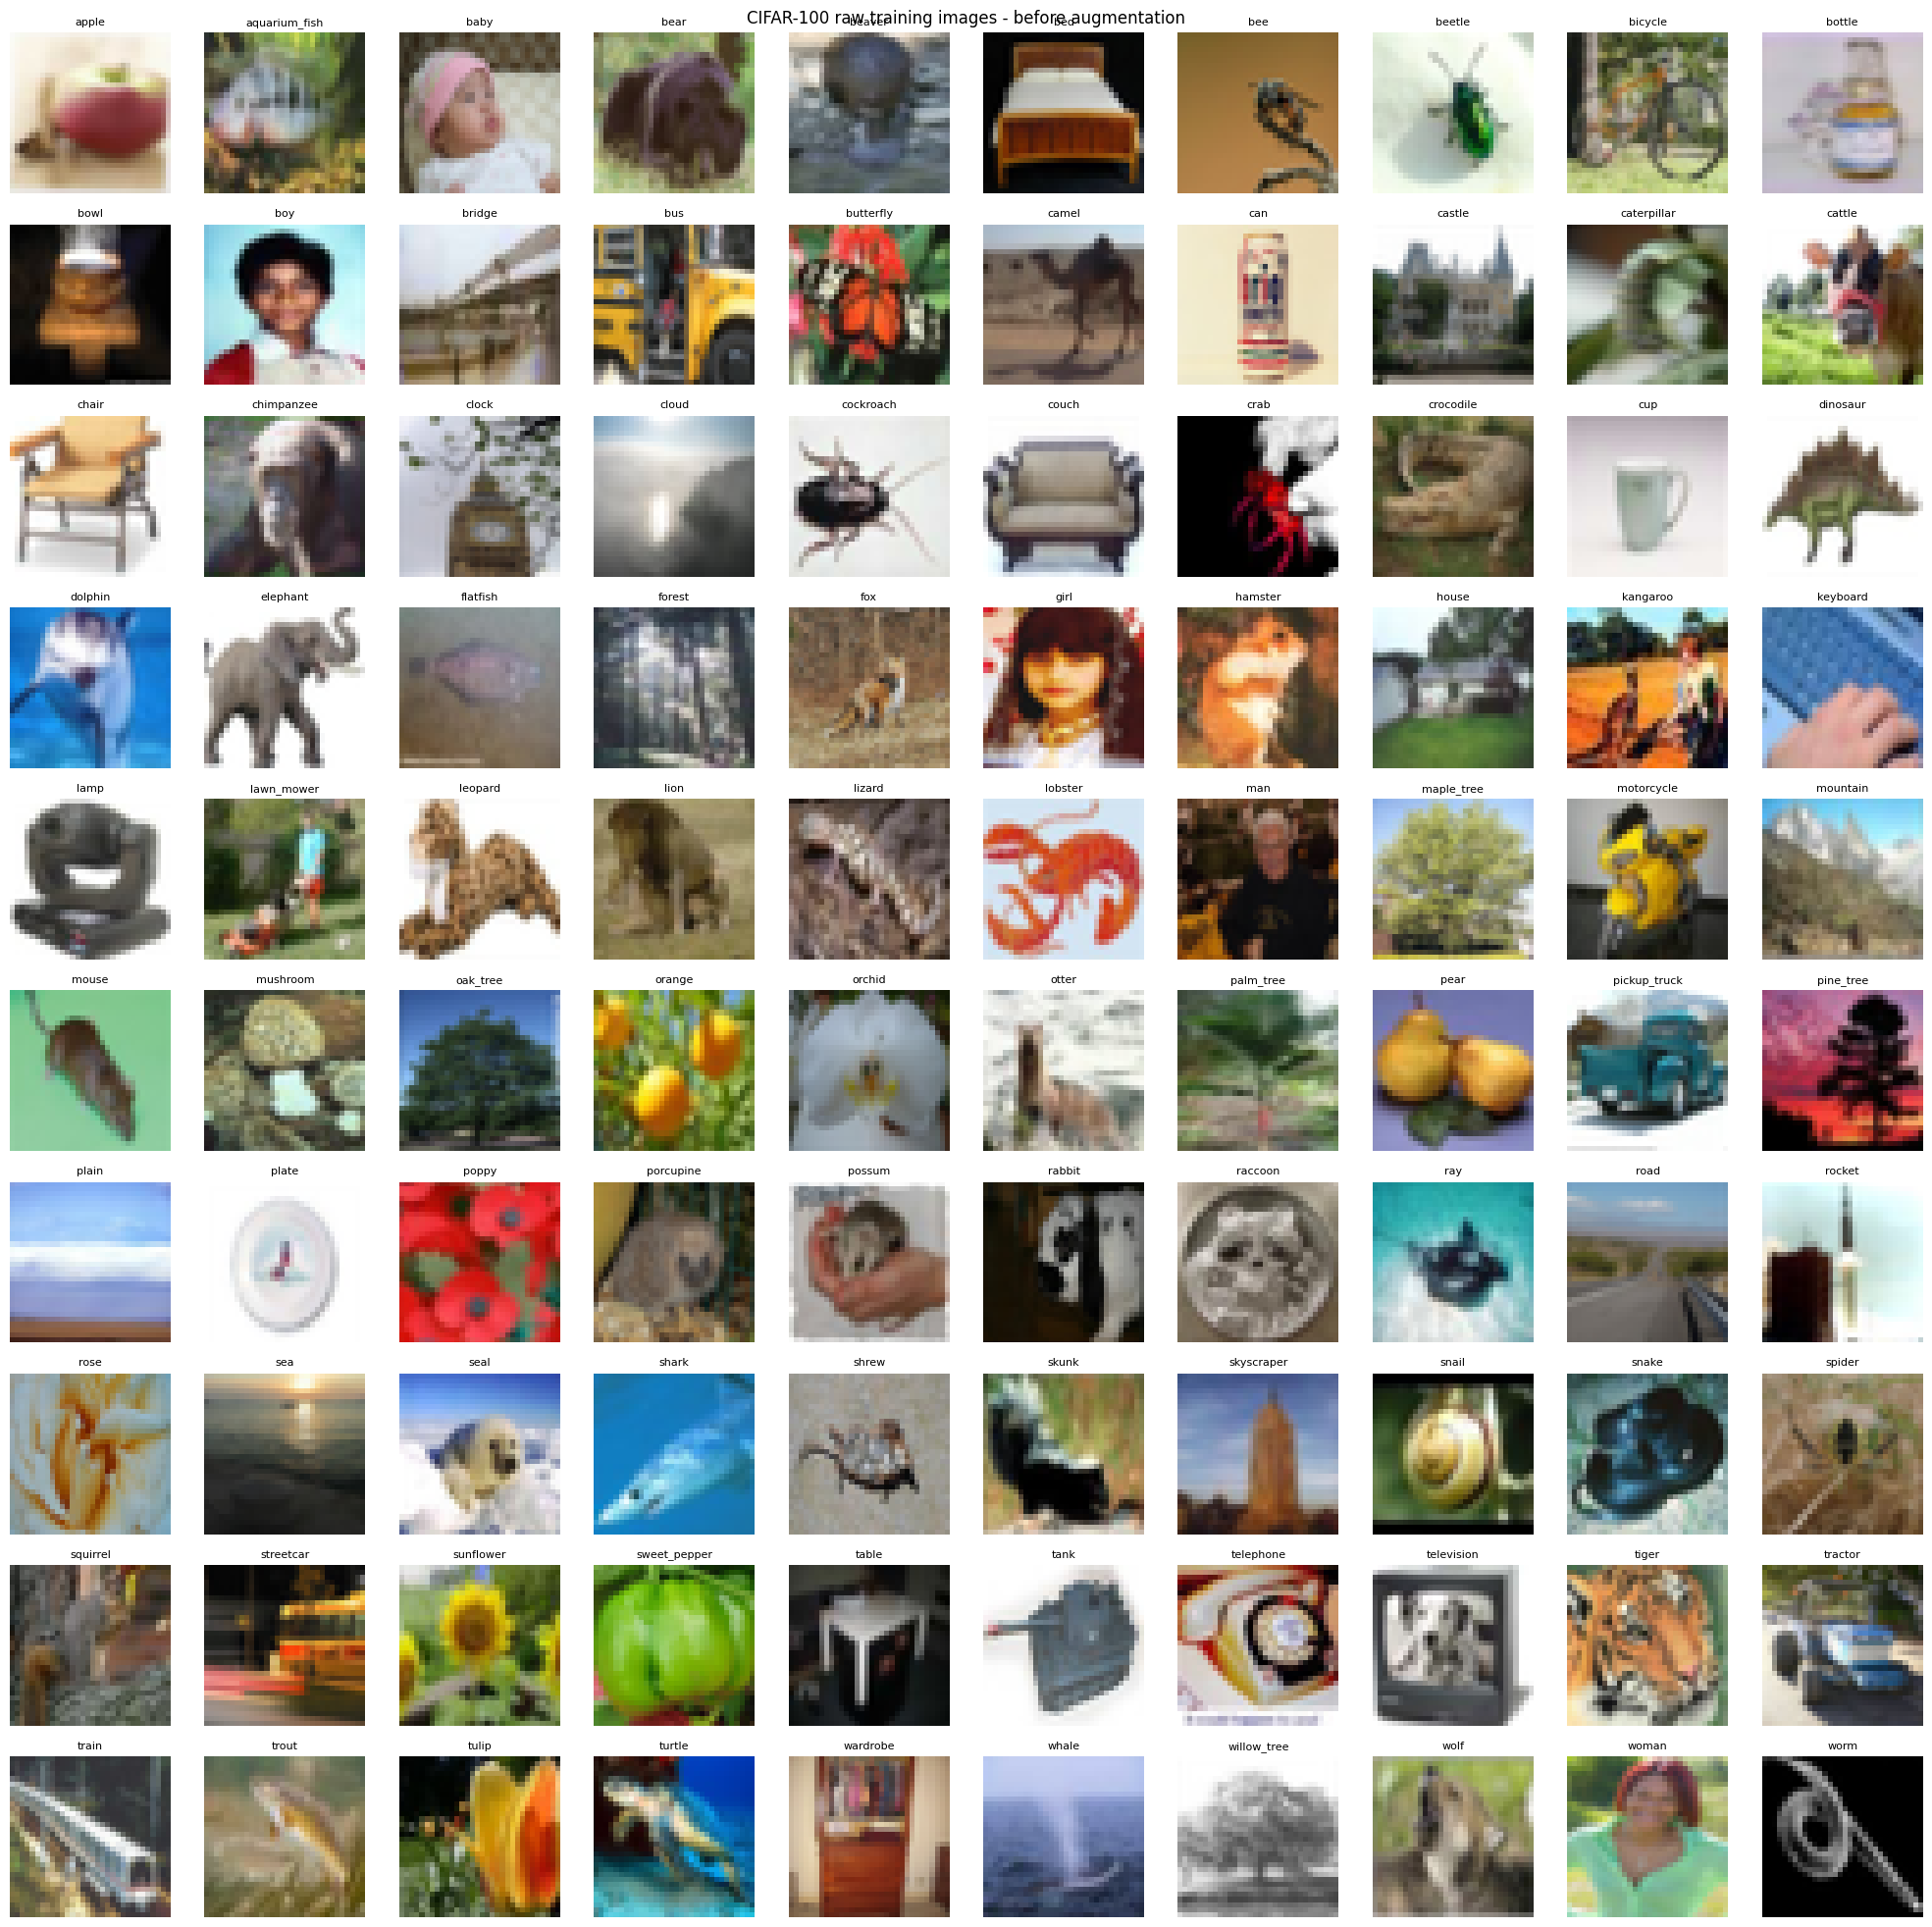

In [6]:
import matplotlib.pyplot as plt

raw_labels = tf.reshape(y_train, [-1])
fig, axes = plt.subplots(10, 10, figsize=(20, 20))

for class_id, axis in enumerate(axes.flat):
    matching_indices = tf.where(raw_labels == class_id)[:, 0]
    sample_index = int(matching_indices[0])
    axis.imshow(x_train[sample_index].numpy())
    axis.set_title(class_names[class_id], fontsize=8)
    axis.axis("off")

fig.suptitle("CIFAR-100 raw training images - before augmentation")
fig.tight_layout()
plt.show()

## Kiểm tra số lượng ảnh theo lớp

Mỗi nhãn là số từ 0 đến 99. Bảng dưới đây đếm số mẫu train và test cho từng lớp.

In [7]:
train_labels = tf.reshape(tf.convert_to_tensor(y_train), [-1])
test_labels = tf.reshape(tf.convert_to_tensor(y_test), [-1])

train_counts = tf.math.bincount(train_labels, minlength=len(class_names), maxlength=len(class_names))
test_counts = tf.math.bincount(test_labels, minlength=len(class_names), maxlength=len(class_names))

for index, name in enumerate(class_names):
    print(
        f"{index}: {name:>15} | "
        f"train={int(train_counts[index]) :>5} | "
        f"test={int(test_counts[index]) :>5}"
    )

0:           apple | train=  500 | test=  100
1:   aquarium_fish | train=  500 | test=  100
2:            baby | train=  500 | test=  100
3:            bear | train=  500 | test=  100
4:          beaver | train=  500 | test=  100
5:             bed | train=  500 | test=  100
6:             bee | train=  500 | test=  100
7:          beetle | train=  500 | test=  100
8:         bicycle | train=  500 | test=  100
9:          bottle | train=  500 | test=  100
10:            bowl | train=  500 | test=  100
11:             boy | train=  500 | test=  100
12:          bridge | train=  500 | test=  100
13:             bus | train=  500 | test=  100
14:       butterfly | train=  500 | test=  100
15:           camel | train=  500 | test=  100
16:             can | train=  500 | test=  100
17:          castle | train=  500 | test=  100
18:     caterpillar | train=  500 | test=  100
19:          cattle | train=  500 | test=  100
20:           chair | train=  500 | test=  100
21:      chimpanzee | t

## Pipeline train/validation/test

Tách 5.000 ảnh validation trước, rồi tính mean/std riêng cho từng kênh RGB
chỉ trên 45.000 ảnh train. Augmentation chạy trên pixel [0, 1] trước khi
chuẩn hóa: flip ngang, random crop, xoay ±5°, dịch chuyển ±5%, zoom ±10%,
và color jitter nhẹ. Validation/test không augment và dùng cùng thống kê train.

In [8]:
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE
VALIDATION_SIZE = 5_000

# Seed cá»‘ Ä‘á»‹nh Ä‘á»ƒ take/skip luÃ´n táº¡o cÃ¹ng phÃ©p chia train/validation.
shuffled_train = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(
    buffer_size=len(x_train), seed=42, reshuffle_each_iteration=False
)
val_raw_ds = shuffled_train.take(VALIDATION_SIZE)
train_raw_ds = shuffled_train.skip(VALIDATION_SIZE)

# TÃ­nh mean/std theo tá»«ng kÃªnh trÃªn train gá»‘c, khÃ´ng dÃ¹ng validation hay test.
channel_sum = tf.zeros([3], dtype=tf.float64)
channel_square_sum = tf.zeros([3], dtype=tf.float64)
pixel_count = tf.constant(0.0, dtype=tf.float64)
for images, _ in train_raw_ds.batch(256):
    images = tf.cast(images, tf.float64) / 255.0
    channel_sum += tf.reduce_sum(images, axis=[0, 1, 2])
    channel_square_sum += tf.reduce_sum(tf.square(images), axis=[0, 1, 2])
    pixel_count += tf.cast(tf.shape(images)[0] * 32 * 32, tf.float64)

channel_mean = channel_sum / pixel_count
channel_variance = channel_square_sum / pixel_count - tf.square(channel_mean)
PIXEL_MEAN = tf.cast(channel_mean, tf.float32)
PIXEL_STD = tf.cast(tf.sqrt(tf.maximum(channel_variance, 1e-12)), tf.float32)
print("Train RGB mean:", PIXEL_MEAN.numpy())
print("Train RGB std :", PIXEL_STD.numpy())

random_rotation = tf.keras.layers.RandomRotation(
    factor=5.0 / 360.0,
    fill_mode="reflect",
    interpolation="bilinear",
    seed=44,
)
random_translation = tf.keras.layers.RandomTranslation(
    height_factor=0.05,
    width_factor=0.05,
    fill_mode="reflect",
    interpolation="bilinear",
    seed=45,
)
random_zoom = tf.keras.layers.RandomZoom(
    height_factor=(-0.1, 0.1),
    width_factor=(-0.1, 0.1),
    fill_mode="reflect",
    interpolation="bilinear",
    seed=46,
)


def normalize_example(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    image = (image - PIXEL_MEAN) / PIXEL_STD
    return image, tf.cast(label, tf.int32)


def augment_example(image, label):
    # Augment tá»«ng áº£nh trong miá»n pixel [0, 1], trÆ°á»›c mean/std.
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.image.random_flip_left_right(image)
    image = tf.pad(image, [[4, 4], [4, 4], [0, 0]], mode="REFLECT")
    image = tf.image.random_crop(image, size=[32, 32, 3])
    image = random_rotation(image, training=True)
    image = random_translation(image, training=True)
    image = random_zoom(image, training=True)
    image = tf.image.random_saturation(image, lower=0.9, upper=1.1)
    image = tf.image.random_hue(image, max_delta=0.02)
    image = tf.image.random_brightness(image, max_delta=0.05)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.clip_by_value(image, 0.0, 1.0)
    image = (image - PIXEL_MEAN) / PIXEL_STD
    return image, tf.cast(label, tf.int32)


train_ds = (
    train_raw_ds
    .shuffle(buffer_size=len(x_train) - VALIDATION_SIZE, seed=43,
             reshuffle_each_iteration=True)
    .map(augment_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

train_clean_ds = (
    train_raw_ds
    .map(normalize_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_raw_ds
    .map(normalize_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test))
    .map(normalize_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print(f"Train: {len(x_train) - VALIDATION_SIZE}")
print(f"Validation: {VALIDATION_SIZE} ")
print(f"Test: {len(x_test)}")

Train RGB mean: [0.5066384  0.48612902 0.44058496]
Train RGB std : [0.267232   0.25635353 0.27604508]

Train: 45000
Validation: 5000 
Test: 10000


## Preview ảnh train sau augmentation




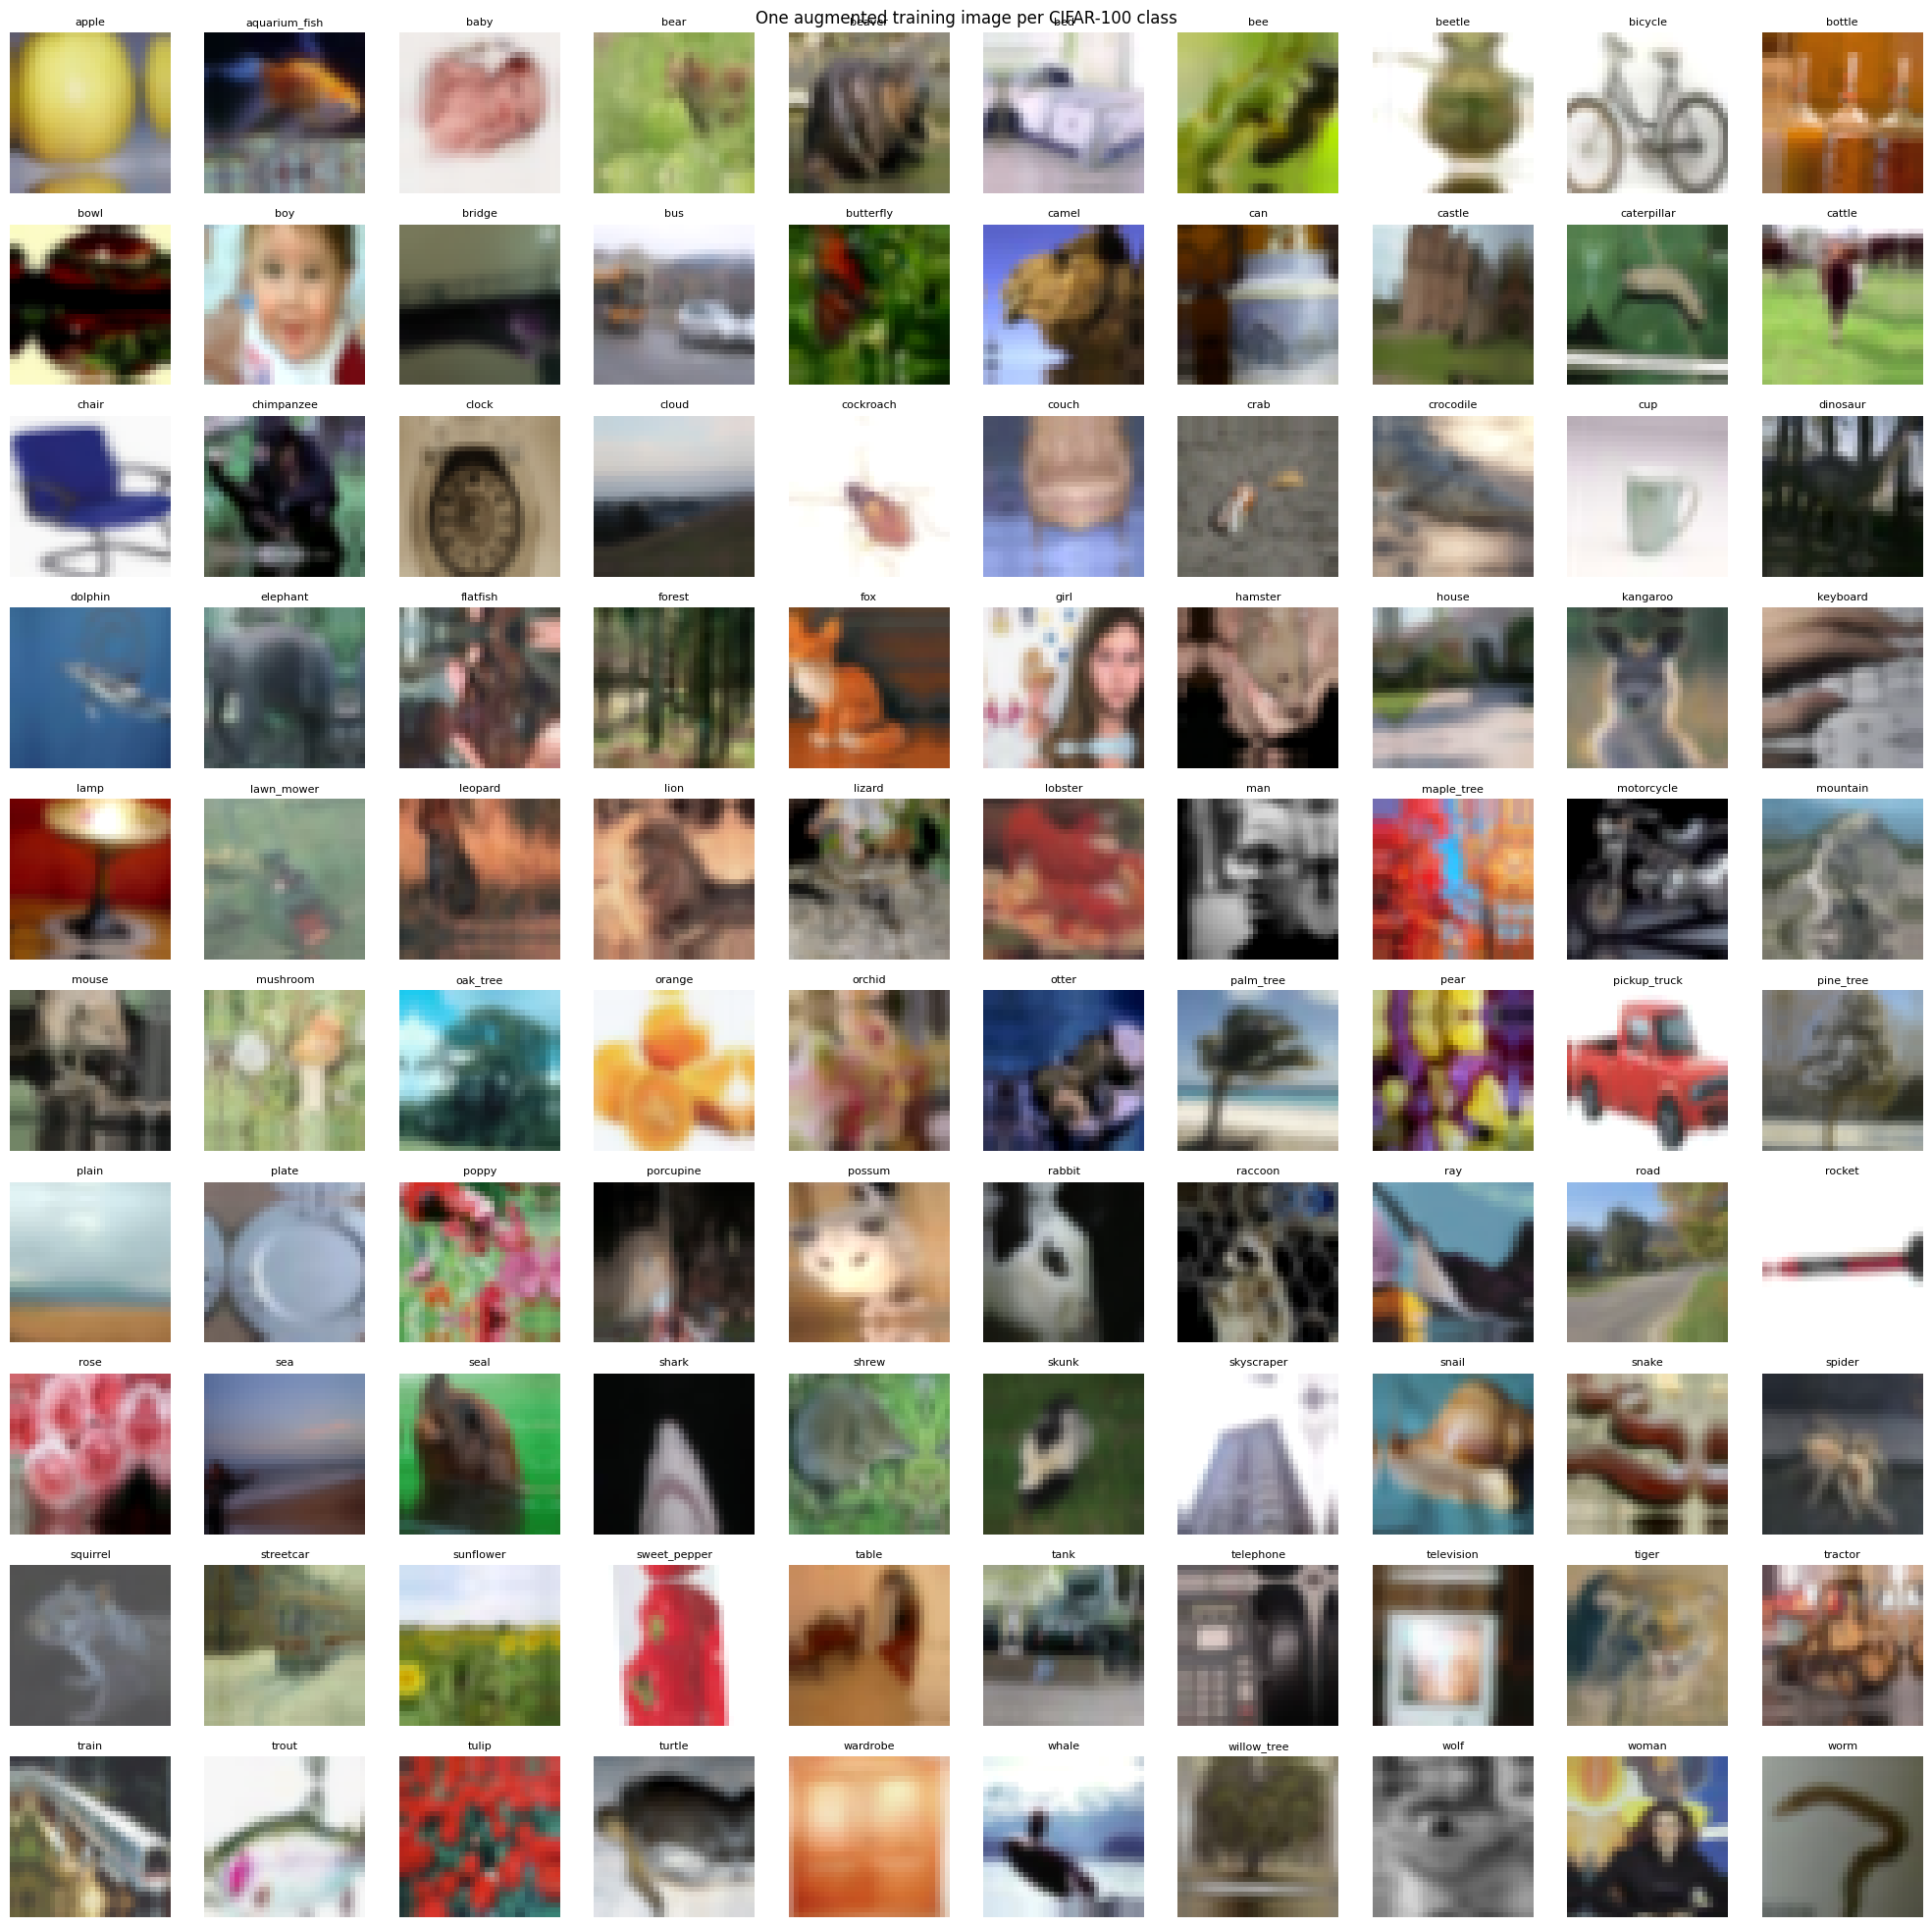

In [9]:
import matplotlib.pyplot as plt

# Lấy một ảnh augmented cho mỗi class, giữ nguyên cặp ảnh-nhãn từ train_ds.
preview_by_class = {}
for batch_images, batch_labels in train_ds:
    for image, label in zip(batch_images, batch_labels):
        class_id = int(label.numpy())
        if class_id not in preview_by_class:
            preview_by_class[class_id] = image
    if len(preview_by_class) == len(class_names):
        break

fig, axes = plt.subplots(10, 10, figsize=(20, 20))
for class_id, axis in enumerate(axes.flat):
    image = preview_by_class[class_id] * PIXEL_STD + PIXEL_MEAN
    image = tf.clip_by_value(image, 0.0, 1.0)
    axis.imshow(image.numpy())
    axis.set_title(class_names[class_id], fontsize=8)
    axis.axis("off")

fig.suptitle("One augmented training image per CIFAR-100 class")
fig.tight_layout()
plt.show()

## CNN theo kiến trúc notebook mẫu

Bốn block có lần lượt 2 Conv2D với 32, 64, 128 và 256 filters; mỗi Conv2D dùng
ReLU, BatchNormalization và L2 weight decay 0.0001. Sau mỗi block là
MaxPooling2D và Dropout (0.2, 0.3, 0.4, 0.5). Cuối model dùng Flatten và Dense
softmax 100 class.

In [10]:
WEIGHT_DECAY = 0.0001

model = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(32, 32, 3)),

        # Block 1: 2 Conv2D layers, 32 filters.
        tf.keras.layers.Conv2D(
            32, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(
            32, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Dropout(0.2),

        # Block 2: 2 Conv2D layers, 64 filters.
        tf.keras.layers.Conv2D(
            64, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(
            64, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Dropout(0.3),

        # Block 3: 2 Conv2D layers, 128 filters.
        tf.keras.layers.Conv2D(
            128, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(
            128, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Dropout(0.4),

        # Block 4: 2 Conv2D layers, 256 filters.
        tf.keras.layers.Conv2D(
            256, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(
            256, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Dropout(0.5),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(len(class_names), activation="softmax"),
    ],
    name="cifar100_vgg_style_cnn",
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

model.summary()


Model: "cifar100_vgg_style_cnn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 32, 32, 32)        896       
                                                                 
 batch_normalization (Batch  (None, 32, 32, 32)        128       
 Normalization)                                                  
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 32)        9248      
                                                                 
 batch_normalization_1 (Bat  (None, 32, 32, 32)        128       
 chNormalization)                                                
                                                                 
 max_pooling2d (MaxPooling2  (None, 16, 16, 32)        0         
 D)                                                              
                                           

## Train và checkpoint theo validation loss

Adam bắt đầu ở learning rate 0.001. ReduceLROnPlateau giảm LR một nửa sau 3 epoch
không cải thiện val_loss, tối thiểu 0.00001. EarlyStopping patience=20 và khôi phục
weights tốt nhất. Giới hạn train là 200 epoch. Checkpoint và CSV history nằm trong
fruit-detection/checkpoints. Checkpoint và history dùng tên riêng cho CIFAR-100.
Tập test không tham gia chọn checkpoint.

In [11]:
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "cifar100_vgg_style_cnn_best.keras"
HISTORY_PATH = CHECKPOINT_DIR / "cifar100_vgg_style_cnn_history.csv"

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(CHECKPOINT_PATH),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)
reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=3,
    min_delta=0.0,
    min_lr=1e-5,
    verbose=1,
)
early_stopping_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=20,
    restore_best_weights=True,
    verbose=1,
)
history_logger_cb = tf.keras.callbacks.CSVLogger(str(HISTORY_PATH), append=False)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=200,
    callbacks=[checkpoint_cb, reduce_lr_cb, early_stopping_cb, history_logger_cb],
)

print(f"Best checkpoint: {CHECKPOINT_PATH}")
print(f"Training history: {HISTORY_PATH}")

Epoch 1/200


704/704 [==============================] - ETA: 0s - loss: 4.9538 - accuracy: 0.0694
Epoch 1: val_loss improved from inf to 4.34841, saving model to D:\22DT3\AI-Projects\fruit-detection\checkpoints\cifar100_vgg_style_cnn_best.keras
704/704 [==============================] - 110s 151ms/step - loss: 4.9538 - accuracy: 0.0694 - val_loss: 4.3484 - val_accuracy: 0.1326 - lr: 0.0010
Epoch 2/200
703/704 [============================>.] - ETA: 0s - loss: 4.2877 - accuracy: 0.1274
Epoch 2: val_loss improved from 4.34841 to 3.84267, saving model to D:\22DT3\AI-Projects\fruit-detection\checkpoints\cifar100_vgg_style_cnn_best.keras
704/704 [==============================] - 116s 164ms/step - loss: 4.2880 - accuracy: 0.1274 - val_loss: 3.8427 - val_accuracy: 0.1428 - lr: 0.0010
Epoch 3/200
703/704 [============================>.] - ETA: 0s - loss: 3.9558 - accuracy: 0.1659
Epoch 3: val_loss did not improve from 3.84267
704/704 [==============================] - 98s 138ms/step - loss: 

## Đường cong huấn luyện

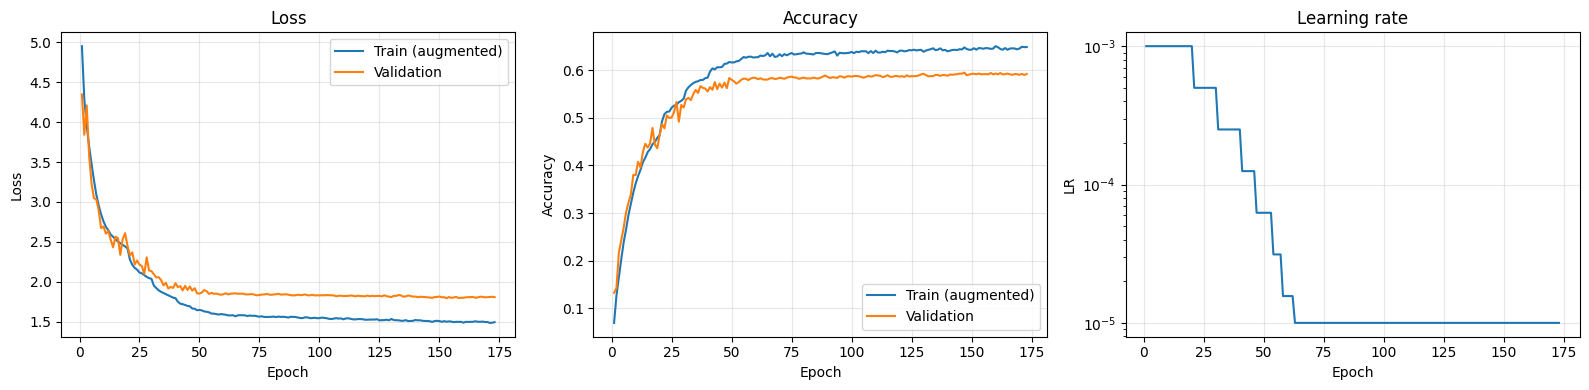

In [12]:
epochs = range(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for axis, metric, title in zip(axes[:2], ["loss", "accuracy"], ["Loss", "Accuracy"]):
    axis.plot(epochs, history.history[metric], label="Train (augmented)")
    axis.plot(epochs, history.history[f"val_{metric}"], label="Validation")
    axis.set(title=title, xlabel="Epoch", ylabel=title)
    axis.legend()
    axis.grid(alpha=0.3)

lr_values = history.history.get("learning_rate", history.history.get("lr"))
if lr_values is not None:
    axes[2].plot(epochs, lr_values)
    axes[2].set_yscale("log")
    axes[2].set(title="Learning rate", xlabel="Epoch", ylabel="LR")
    axes[2].grid(alpha=0.3)
else:
    axes[2].set_visible(False)

fig.tight_layout()
plt.show()

In [13]:
best_model = tf.keras.models.load_model(str(CHECKPOINT_PATH))
train_clean_metrics = best_model.evaluate(train_clean_ds, return_dict=True, verbose=1)
val_metrics = best_model.evaluate(val_ds, return_dict=True, verbose=1)

print("Train khÃ´ng augment:", train_clean_metrics)
print("Validation:", val_metrics)
print(f"Accuracy gap (train - val): "
      f"{train_clean_metrics['accuracy'] - val_metrics['accuracy']:.4f}")

79/79 [==============================] - 3s 37ms/step - loss: 1.7932 - accuracy: 0.5930
Train khÃ´ng augment: {'loss': 1.196811318397522, 'accuracy': 0.727400004863739}
Validation: {'loss': 1.7932376861572266, 'accuracy': 0.5929999947547913}
Accuracy gap (train - val): 0.1344
